# Vowel inventory of a text (Kokoro tokens)

1. **Text → tokens:** the same G2P Kokoro uses (`text_to_ipa_chunks`), plus the token ids the model receives.
2. **Tokens → phonemes:** stress marks are assigned to the vowel they belong to, length (ː) and nasality (̃)
   are attached to their vowel, and each vowel gets its word and position.
3. **Measure and plot:** top vowels, a vowel chart (IPA trapezoid), stress, position in the word, long vowels and
   vowel sequences (hiatus / diphthongs).

Consonants are kept in the table (so the share of vowels can be computed) but every count and plot uses vowels only.

In [1]:
from functions import *          # text_to_ipa_chunks, check_ipa, VOCAB, CONSONANTS, VOWELS, SKIP, BOUNDARY ...
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

c:\Users\utente\anaconda3\envs\koko\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\utente\anaconda3\envs\koko\Lib\site-packages\torch\nn\modules\rnn.py:123: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.2 and num_layers=1
  warnings.warn(
c:\Users\utente\anaconda3\envs\koko\Lib\site-packages\torch\nn\utils\weight_norm.py:143: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


## 1. Settings

| setting | meaning |
|---|---|
| `text` | your text (or read it from a file, see the comment) |
| `TOP_N` | how many vowels to show in the plots |
| `length` | `"ignore"`: aː counts as a. `"separate"`: aː is its own vowel |
| `keep_nasal` | `True`: ã and a are different vowels. `False`: ã counts as a |
| `vowel_map` | merge symbols before counting, e.g. `{"ɪ": "i"}` to count espeak's reduced ɪ as i |

In [2]:
text = '''Il gatto dorme sotto il ramo verde. Maria compra il pane fresco ogni mattina.
Il treno parte alle otto di sera. Mio fratello studia la storia a Roma.'''
text = Path("story1_new.txt").read_text(encoding="utf-8")

TOP_N      = 15
length     = "ignore"      # "ignore" | "separate"
keep_nasal = True
vowel_map  = {}            # e.g. {"ɪ": "i"}

out_dir = Path("vowel_out"); out_dir.mkdir(exist_ok=True)

## 2. Text → Kokoro tokens

`text_to_ipa_chunks` gives one IPA string per sentence, exactly what the model would read.
`check_ipa` shows the token ids and warns if any character is not in Kokoro's vocabulary (it would be dropped).

In [3]:
chunks = text_to_ipa_chunks(text)
for i, ps in enumerate(chunks):
    print(f"[{i}] {ps}")
print()
check_ipa(chunks);

[0] ˈɛːlena markˈetːɪ lavorˈava da sˌɛi ˈannɪ nellarkˈivio komʊnˈale dɪ pontevˈɛrde, ˌʊna pˈikːola ʧitːˈa kostrʊˈita lˈuŋɡo ʊn fjˈume nˈella pjanˈura del nˈɔrd.
[1] larkˈivio okːʊpˈava il tˈɛrʦo pjˈano dɪ ʊn vˈɛkːio palˈaʦːo dɪ matːˈonɪ rˈoSɪ, a pˈɔkɪ pˈaSɪ dˌalla pjˈaʦːa prinʧipˈale e dal mʊniʧˈipio.
[2] il palˈaʦːo ˌɛra stˈato kostrʊˈito ˌalla fˈine dellotːoʧˈɛnto, e in paSˈato avˌeva ospitˈato ˌʊna skʊˈɔla e pˈɔi alkˌʊnɪ ʊffˈiʧɪ del tribʊnˈale.
[3] la sˈala pjʊ ɡrˈande avˌeva soffˈitːɪ ˈaltɪ, skaffˈalɪ dɪ lˈeɲɲo skˈuro e dˈue lˈuŋɡe finˈɛstre ke ɡwardˈavano vˌɛrso il fjˈume.
[4] in kwˌella sˈala sɪ trovˈavano i reʤˈistrɪ dˌelle nˈaʃite, dˌA matrimˈonɪ e dˌelle proprietˈa, alkˌʊnɪ dˌA kwˈalɪ avˈevano pjʊ dɪ dʊeʧˈɛnto ˈannɪ.
[5] il lavˈɔro dɪ ˈɛːlena konsistˈɛva nel kataloɡˈare i dokʊmˈentɪ, nel rispˈondere ˌalle rikjˈɛste dˌA ʧitːadˈinɪ e nel tenˈere in ˈɔrdine le sˈale.
[6] ˌoɲɲɪ matːˈina arɾivˈava ˌalle ˈɔtːo, aʧːendˈɛva le lˈuʧɪ, aprˈiva le finˈɛstre per kwˈalke minˈuto e kontroll

In [4]:
def token_kind(c):
    if c in VOWELS: return "vowel"
    if c in CONSONANTS: return "consonant"
    if c in SKIP: return "stress/diacritic"
    if c == " ": return "space"
    if c in BOUNDARY: return "punctuation"
    return "other"

tokens = pd.DataFrame([{"chunk": ci, "pos": i, "char": c, "id": VOCAB.get(c), "kind": token_kind(c)}
                       for ci, ps in enumerate(chunks) for i, c in enumerate(ps)])
print(f"{len(tokens)} tokens in {len(chunks)} chunks")
display(tokens["kind"].value_counts().to_frame("tokens"))
tokens.head(20)

14383 tokens in 106 chunks


,tokens
kind,
consonant,5438
vowel,4842
space,2096
stress/diacritic,1732
punctuation,275


,chunk,pos,char,id,kind
0,0,0,ˈ,156,stress/diacritic
1,0,1,ɛ,86,vowel
2,0,2,ː,158,stress/diacritic
3,0,3,l,54,consonant
4,0,4,e,47,vowel
5,0,5,n,56,consonant
6,0,6,a,43,vowel
7,0,7,,16,space
8,0,8,m,55,consonant
9,0,9,a,43,vowel


## 3. Tokens → phonemes

| function | what it does |
|---|---|
| `segment(ps)` | Walks one IPA string and returns one record per phoneme: the symbol, whether it is long (ː) or nasal (̃), its stress (a ˈ / ˌ mark applies to the **next vowel** in the same word), its word, and whether it is a vowel. Affricates (tʃ …) are joined so consonant counts in the summary are right. |
| `add_position(rows)` | Marks each phoneme as word-initial, medial or final. |
| `VOWEL_INFO` | Height, backness and rounding of every vowel in Kokoro's vocabulary, used for the vowel chart and the class tables. Misaki's one-letter diphthongs (A, I, O, W, Q, Y, mostly English) are marked as diphthongs. |
| `label(row)` | The name a vowel is counted under, following the settings above. |

In [5]:
AFFRICATES_2 = {"tʃ", "ts", "dʒ", "dz"}
NASAL, LENGTH = "̃", "ː"

# symbol: (height, backness, rounded)   height: 0 close … 6 open,  backness: 0 front, 1 central, 2 back
VOWEL_INFO = {
    "i": (0, 0, False), "y": (0, 0, True),  "ɨ": (0, 1, False), "ɯ": (0, 2, False), "u": (0, 2, True),
    "ɪ": (1, 0.3, False), "ᵻ": (1, 1, False), "ʊ": (1, 1.7, True),
    "e": (2, 0, False), "ø": (2, 0, True),  "ɤ": (2, 2, False), "o": (2, 2, True),
    "ə": (3, 1, False), "ᵊ": (3, 1, False), "ɚ": (3, 1, False),
    "ɛ": (4, 0, False), "œ": (4, 0, True),  "ɜ": (4, 1, False), "ʌ": (4, 2, False), "ɔ": (4, 2, True),
    "æ": (5, 0, False), "ɐ": (5, 1, False),
    "a": (6, 0, False), "ɑ": (6, 2, False), "ɒ": (6, 2, True),
}
DIPHTHONGS = {"A": "eɪ", "I": "aɪ", "O": "oʊ", "W": "aʊ", "Q": "əʊ", "Y": "ɔɪ"}   # misaki letters
HEIGHT = {0: "close", 1: "near-close", 2: "close-mid", 3: "mid", 4: "open-mid", 5: "near-open", 6: "open"}

def vclass(v):
    if v in DIPHTHONGS: return ("diphthong", "diphthong", "diphthong")
    h, b, r = VOWEL_INFO.get(v, (None, None, None))
    if h is None: return ("other", "other", "other")
    back = "front" if b < 0.5 else ("central" if b < 1.5 else "back")
    return (HEIGHT[h], back, "rounded" if r else "unrounded")

def segment(ps, chunk=0):
    rows, word, i, gap, stress = [], -1, 0, True, None
    while i < len(ps):
        c = ps[i]
        if c in BOUNDARY:
            gap, stress = True, None; i += 1; continue
        if gap:
            word += 1; gap = False
        if c in ("ˈ", "ˌ"):
            stress = "primary" if c == "ˈ" else "secondary"; i += 1; continue
        if c not in (VOWELS | CONSONANTS):
            i += 1; continue
        base, j = c, i + 1
        if ps[i:i + 2] in AFFRICATES_2:
            base, j = ps[i:i + 2], i + 2
        long_, nasal = False, False
        while j < len(ps) and ps[j] in (LENGTH, NASAL, "ʰ", "ʲ"):
            long_ |= ps[j] == LENGTH; nasal |= ps[j] == NASAL; j += 1
        is_vowel = base in VOWELS
        st = None
        if is_vowel:
            st, stress = (stress or "unstressed"), None     # the mark is used up by this vowel
        rows.append({"chunk": chunk, "word": word, "base": vowel_map.get(base, base) if is_vowel else base,
                     "long": long_ or base == "S", "nasal": nasal, "vowel": is_vowel, "stress": st})
        i = j
    return rows

def add_position(rows):
    for k, r in enumerate(rows):
        same = lambda q: 0 <= q < len(rows) and rows[q]["chunk"] == r["chunk"] and rows[q]["word"] == r["word"]
        r["position"] = "initial" if not same(k - 1) else ("final" if not same(k + 1) else "medial")
    return rows

def label(r):
    s = r["base"]
    if keep_nasal and r["nasal"]: s += NASAL
    if length == "separate" and r["long"]: s += LENGTH
    return s

rows = []
for ci, ps in enumerate(chunks):
    rows += segment(ps, ci)
ph = pd.DataFrame(add_position(rows))
ph["phoneme"] = ph.apply(label, axis=1)

vow = ph[ph["vowel"]].copy()
vow[["height", "backness", "rounding"]] = pd.DataFrame(vow["base"].map(vclass).tolist(), index=vow.index)
n_all, n_vow = len(ph), len(vow)
print(f"phonemes: {n_all}   vowels: {n_vow} ({100*n_vow/n_all:.1f}%)   consonants: {n_all - n_vow}   "
      f"different vowels: {vow['phoneme'].nunique()}")
vow.head(20)

phonemes: 10280   vowels: 4842 (47.1%)   consonants: 5438   different vowels: 11


,chunk,word,base,long,nasal,vowel,stress,position,phoneme,height,backness,rounding
0,0,0,ɛ,True,False,True,primary,initial,ɛ,open-mid,front,unrounded
2,0,0,e,False,False,True,unstressed,medial,e,close-mid,front,unrounded
4,0,0,a,False,False,True,unstressed,final,a,open,front,unrounded
6,0,1,a,False,False,True,unstressed,medial,a,open,front,unrounded
9,0,1,e,False,False,True,primary,medial,e,close-mid,front,unrounded
11,0,1,ɪ,False,False,True,unstressed,final,ɪ,near-close,front,unrounded
13,0,2,a,False,False,True,unstressed,medial,a,open,front,unrounded
15,0,2,o,False,False,True,unstressed,medial,o,close-mid,back,rounded
17,0,2,a,False,False,True,primary,medial,a,open,front,unrounded
19,0,2,a,False,False,True,unstressed,final,a,open,front,unrounded


## 4. Top vowels

,count,percent,height,backness,rounding
phoneme,,,,,
a,1315,27.2,open,front,unrounded
e,1039,21.5,close-mid,front,unrounded
o,946,19.5,close-mid,back,rounded
i,586,12.1,close,front,unrounded
ɪ,302,6.2,near-close,front,unrounded
ɛ,221,4.6,open-mid,front,unrounded
ʊ,215,4.4,near-close,back,rounded
ɔ,102,2.1,open-mid,back,rounded
u,97,2.0,close,back,rounded


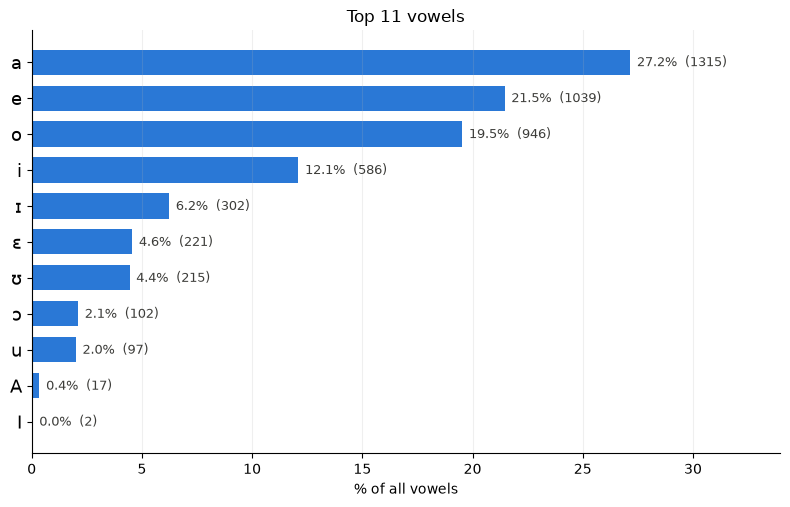

In [6]:
counts = vow["phoneme"].value_counts().rename("count").to_frame()
counts["percent"] = 100 * counts["count"] / n_vow
first = vow.groupby("phoneme")["base"].first()
counts[["height", "backness", "rounding"]] = [vclass(first[p]) for p in counts.index]
counts.to_csv(out_dir / "vowel_counts.csv")
display(counts.round(1))

top = counts.head(TOP_N)[::-1]
fig, ax = plt.subplots(figsize=(8, 0.38 * len(top) + 1))
bars = ax.barh(top.index, top["percent"], color="#2a78d6", height=0.7)
for b, n in zip(bars, top["count"]):
    ax.text(b.get_width() + 0.3, b.get_y() + b.get_height() / 2, f"{b.get_width():.1f}%  ({n})",
            va="center", fontsize=9, color="#3d3d3a")
ax.set_xlabel("% of all vowels"); ax.set_title(f"Top {len(top)} vowels")
ax.tick_params(axis="y", labelsize=13)
for s in ("top", "right"): ax.spines[s].set_visible(False)
ax.grid(axis="x", alpha=.2); ax.set_xlim(0, top["percent"].max() * 1.25)
plt.tight_layout(); plt.savefig(out_dir / "top_vowels.png", dpi=150); plt.show()

## 5. Vowel chart

Each vowel is placed on the IPA vowel trapezoid (top = close, bottom = open, left = front, right = back).
The circle area is proportional to its frequency. Rounded and unrounded vowels of the same height and backness sit side by side (rounded to the right).
Nasal / long variants are pooled with their base vowel here. Diphthongs (if any) are listed under the chart.

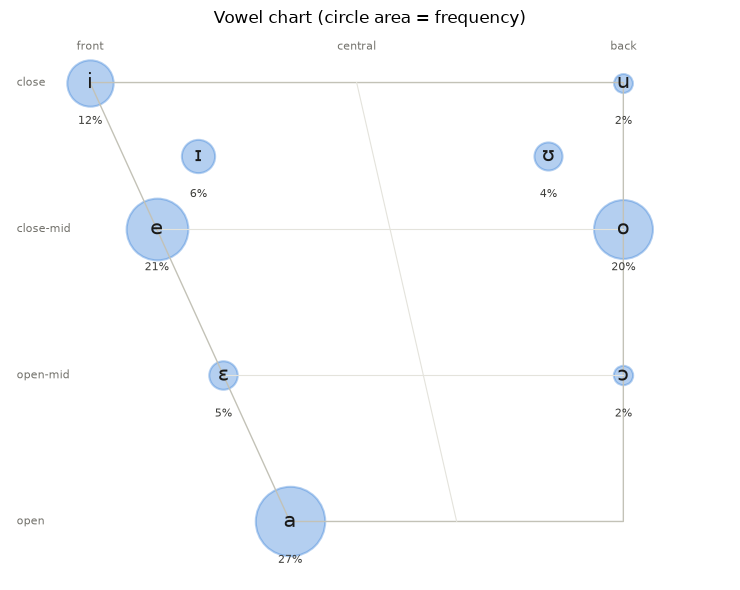

diphthongs (misaki letters): {'A = eɪ': 17, 'I = aɪ': 2}


In [7]:
def chart_xy(h, b, rounded):
    left = 3 * h / 6 * 0.5                       # front edge slants to the right going down
    x = left + (4 - left) * b / 2
    if b >= 1.5:                                 # back: rounded on the edge, unrounded inside
        return x - (0 if rounded else 0.3), -h
    return x + (0.3 if rounded else 0), -h        # front/central: rounded partner to the right

base_counts = vow["base"].value_counts()
fig, ax = plt.subplots(figsize=(7.5, 6))
ax.plot([0, 4, 4, 1.5, 0], [0, 0, -6, -6, 0], color="#c3c2b7", lw=1)           # trapezoid
for h in (2, 4):                                                                 # mid lines
    l = 3 * h / 6 * 0.5; ax.plot([l, 4], [-h, -h], color="#e4e3dc", lw=.8)
ax.plot([2, 2.75], [0, -6], color="#e4e3dc", lw=.8)                              # central line
smax = base_counts.max()
for v, n in base_counts.items():
    if v not in VOWEL_INFO: continue
    x, y = chart_xy(*VOWEL_INFO[v])
    ax.scatter(x, y, s=2500 * n / smax, color="#2a78d6", alpha=.35, edgecolor="#2a78d6", lw=1.5)
    ax.text(x, y, v, ha="center", va="center", fontsize=15, color="#1a1a19")
    ax.text(x, y - 0.45, f"{100*n/n_vow:.0f}%", ha="center", va="top", fontsize=8, color="#3d3d3a")
ax.set_xlim(-0.6, 4.8); ax.set_ylim(-6.8, 0.7); ax.axis("off")
ax.set_title("Vowel chart (circle area = frequency)")
for name, y in [("close", 0), ("close-mid", -2), ("open-mid", -4), ("open", -6)]:
    ax.text(-0.55, y, name, fontsize=8, color="#73726c", va="center")
for name, x in [("front", 0), ("central", 2), ("back", 4)]:
    ax.text(x, 0.45, name, fontsize=8, color="#73726c", ha="center")
plt.tight_layout(); plt.savefig(out_dir / "vowel_chart.png", dpi=150); plt.show()

dip = base_counts[[v for v in base_counts.index if v in DIPHTHONGS]]
if len(dip):
    print("diphthongs (misaki letters):", {f"{v} = {DIPHTHONGS[v]}": int(n) for v, n in dip.items()})

## 6. Vowel classes

In [8]:
for col, order in [("height", list(HEIGHT.values()) + ["diphthong", "other"]),
                   ("backness", ["front", "central", "back", "diphthong", "other"]),
                   ("rounding", ["unrounded", "rounded", "diphthong", "other"])]:
    c = vow[col].value_counts().reindex(order).dropna().astype(int)
    display(pd.DataFrame({"count": c, "percent": (100 * c / n_vow).round(1)}).rename_axis(col))

,count,percent
height,,
close,683,14.1
near-close,517,10.7
close-mid,1985,41.0
open-mid,323,6.7
open,1315,27.2
diphthong,19,0.4


,count,percent
backness,,
front,3463,71.5
back,1360,28.1
diphthong,19,0.4


,count,percent
rounding,,
unrounded,3463,71.5
rounded,1360,28.1
diphthong,19,0.4


## 7. Stress

How often each vowel is stressed. Kokoro/espeak put the stress mark (ˈ primary, ˌ secondary) right before the stressed vowel.

all vowels: {'unstressed': '69.1%', 'primary': '25.9%', 'secondary': '5.0%'}


stress,primary,secondary,unstressed,total
phoneme,,,,
a,412,44,859,1315
e,168,61,810,1039
o,139,25,782,946
i,155,0,431,586
ɪ,0,0,302,302
ɛ,180,41,0,221
ʊ,0,53,162,215
ɔ,97,5,0,102
u,97,0,0,97


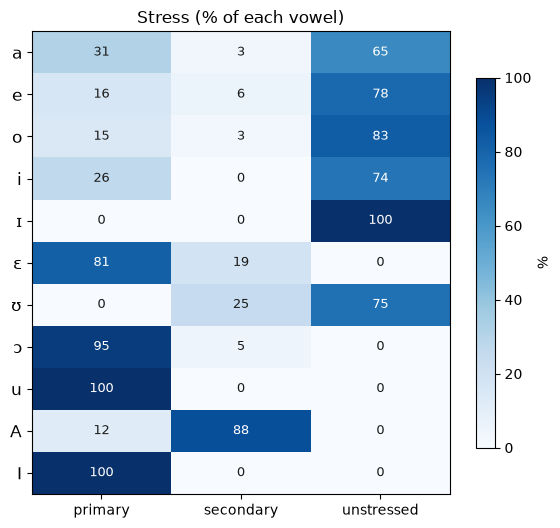

In [9]:
order = counts.head(TOP_N).index
st = (vow[vow["phoneme"].isin(order)]
      .pivot_table(index="phoneme", columns="stress", values="word", aggfunc="count", fill_value=0)
      .reindex(index=order, columns=["primary", "secondary", "unstressed"], fill_value=0))
st_pct = 100 * st.div(st.sum(axis=1), axis=0)
tot = vow["stress"].value_counts()
print("all vowels:", {k: f"{100*v/n_vow:.1f}%" for k, v in tot.items()})
display(st.assign(total=st.sum(axis=1)))

def heat(table_pct, title, fname):
    fig, ax = plt.subplots(figsize=(5.8, 0.38 * len(table_pct) + 1.2))
    im = ax.imshow(table_pct.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
    ax.set_xticks(range(table_pct.shape[1]), table_pct.columns)
    ax.set_yticks(range(len(table_pct)), table_pct.index, fontsize=12)
    for i in range(table_pct.shape[0]):
        for j in range(table_pct.shape[1]):
            v = table_pct.values[i, j]
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=9,
                    color="white" if v > 60 else "#1a1a19")
    ax.set_title(title); fig.colorbar(im, ax=ax, label="%", shrink=0.8)
    plt.tight_layout(); plt.savefig(out_dir / fname, dpi=150); plt.show()

heat(st_pct, "Stress (% of each vowel)", "vowel_stress.png")

## 8. Where in the word?

Each row shows how one vowel's occurrences split over word-initial, medial and final position (rows sum to 100%).

position,initial,medial,final,total
phoneme,,,,
a,252,616,447,1315
e,118,530,391,1039
o,35,394,517,946
i,134,418,34,586
ɪ,0,5,297,302
ɛ,62,159,0,221
ʊ,67,133,15,215
ɔ,3,97,2,102
u,2,95,0,97


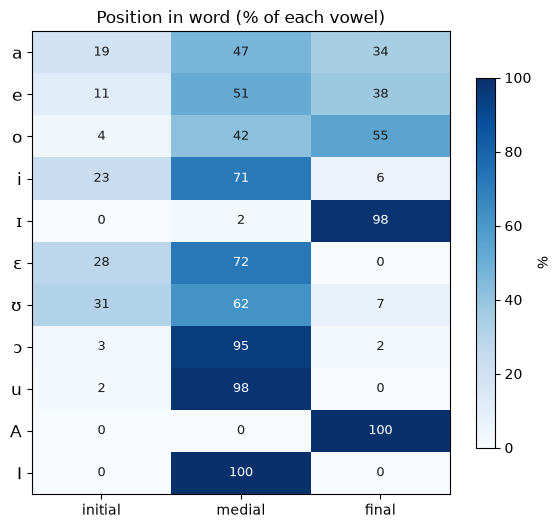

In [10]:
pos = (vow[vow["phoneme"].isin(order)]
       .pivot_table(index="phoneme", columns="position", values="word", aggfunc="count", fill_value=0)
       .reindex(index=order, columns=["initial", "medial", "final"], fill_value=0))
display(pos.assign(total=pos.sum(axis=1)))
heat(100 * pos.div(pos.sum(axis=1), axis=0), "Position in word (% of each vowel)", "vowel_position.png")

## 9. Long and nasal vowels

In [11]:
for col in ("long", "nasal"):
    sub = vow[vow[col]]
    print(f"{col}: {len(sub)} ({100*len(sub)/n_vow:.1f}% of vowels)")
    if len(sub):
        g = sub["base"].value_counts().rename(col).to_frame()
        g["of all occurrences %"] = [100 * g.loc[b, col] / (vow["base"] == b).sum() for b in g.index]
        display(g.round(1))

long: 31 (0.6% of vowels)


,long,of all occurrences %
base,,
ɛ,27,12.2
a,4,0.3


nasal: 0 (0.0% of vowels)


## 10. Vowel sequences (hiatus / diphthongs)

Two or more vowels in a row inside one word, e.g. *Maria* → `iːa`, *studia* → `ia`.

In [12]:
seqs = []
for (ci, w), grp in ph.groupby(["chunk", "word"], sort=False):
    run = []
    for r in list(grp.itertuples()) + [None]:
        if r is not None and r.vowel:
            run.append(r.phoneme)
        else:
            if len(run) >= 2: seqs.append("".join(run))
            run = []
seq_counts = pd.Series(seqs, dtype=object).value_counts().rename("count").to_frame()
print(f"{len(seqs)} vowel sequences, {len(seq_counts)} different")
seq_counts.head(TOP_N)

149 vowel sequences, 21 different


,count
io,40
ʊɔ,18
ao,11
aʊ,10
ia,9
ɔi,8
ɛi,7
ei,7
ʊi,6
ue,5


## 11. Find where a vowel occurs

Lists every word (as IPA) containing the vowel, so you can check the counting.

In [13]:
FIND = "ɛ"

def ipa_words(ps):
    return [w for w in re.split(r"[ " + re.escape("".join(BOUNDARY - {' '})) + r"]+", ps) if w]

hits = vow[vow["phoneme"] == FIND]
words = {ci: ipa_words(ps) for ci, ps in enumerate(chunks)}
print(f"'{FIND}': {len(hits)} occurrences in {hits[['chunk','word']].drop_duplicates().shape[0]} words")
for (ci, w), g in hits.groupby(["chunk", "word"], sort=False):
    wd = words[ci][w] if w < len(words[ci]) else "?"
    print(f"  chunk {ci}: {wd:16s} stress: {', '.join(g['stress'])}")

'ɛ': 221 occurrences in 221 words
  chunk 0: ˈɛːlena          stress: primary
  chunk 0: sˌɛi             stress: secondary
  chunk 0: pontevˈɛrde      stress: primary
  chunk 1: tˈɛrʦo           stress: primary
  chunk 1: vˈɛkːio          stress: primary
  chunk 2: ˌɛra             stress: secondary
  chunk 2: dellotːoʧˈɛnto   stress: primary
  chunk 3: finˈɛstre        stress: primary
  chunk 3: vˌɛrso           stress: secondary
  chunk 4: dʊeʧˈɛnto        stress: primary
  chunk 5: ˈɛːlena          stress: primary
  chunk 5: konsistˈɛva      stress: primary
  chunk 5: rikjˈɛste        stress: primary
  chunk 6: aʧːendˈɛva       stress: primary
  chunk 6: finˈɛstre        stress: primary
  chunk 7: sˈɛtːe           stress: primary
  chunk 7: ˌɛra             stress: secondary
  chunk 8: lˌɛi             stress: secondary
  chunk 8: potˈɛva          stress: primary
  chunk 8: sˌɛnʦa           stress: secondary
  chunk 8: ˈɛSere           stress: primary
  chunk 9: lˌɛi             st